<a href="https://colab.research.google.com/github/LuckySevenn/DAFT-BrainLat-AD-Classification/blob/main/notebooks/descriptivos_brainlat_adni.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Descriptivos BrainLat vs ADNI (CN y AD) — boxplots y tabla demográfica para LaTeX

Mismo formato de CSV maestro que `rf_xgboost_colab.ipynb` / `run_ftt.py`: `MRI_ID`, `DX` (AD codificado como `"Dementia"`), `split`, `sex`, `age`, `years_education` y las 16 estructuras de FreeSurfer.

Este cuaderno genera:

1. **Boxplots por estructura de FreeSurfer**, BrainLat vs ADNI, separados por grupo (CN / AD). Se exporta un PDF por estructura y una figura panel con todas, listos para `\includegraphics`.
2. **Tabla demográfica en LaTeX** (N, edad, sexo, educación) por dataset y grupo, con `booktabs`.

Ejecuta las celdas en orden. En la Parte 3 se abre un botón para seleccionar el CSV de **BrainLat** y en la Parte 4 el de **ADNI**.

## Parte 1 — Importaciones

In [ ]:
import io
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

from google.colab import files

# PDFs con fuentes TrueType embebidas (texto seleccionable y sin problemas en LaTeX/Overleaf)
matplotlib.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "mathtext.fontset": "dejavuserif",
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

pandas 2.2.3 | matplotlib 3.10.0


## Parte 2 — Configuración

Mismos nombres de columnas que `run_ftt.py`. Aquí se definen las estructuras a graficar, sus nombres para las figuras y la tabla, los colores y las opciones de exportación.

In [ ]:
ID_COL = "MRI_ID"
LABEL_COL = "DX"
SPLIT_COL = "split"
POSITIVE, NEGATIVE = "Dementia", "CN"   # en DX, AD está codificado como "Dementia"
GROUPS = ["CN", "AD"]                   # orden de los grupos en figuras y tabla
DATASETS = ["BrainLat", "ADNI"]         # orden de los datasets

# Particiones que se usan para los descriptivos. None = todos los sujetos del CSV (recomendado
# para describir la muestra). Ejemplo para usar solo test: SPLITS_TO_USE = ["test"]
SPLITS_TO_USE = None

# --- Estructuras de FreeSurfer (columna -> nombre legible; "Esp." = espesor cortical). Volúmenes en mm³, espesores en mm.
STRUCTURES = {
    "hippocampus_L":     "L hippocampus",
    "hippocampus_R":     "R hippocampus",
    "lat_ventricle_L":   "L lateral ventricle",
    "lat_ventricle_R":   "R lateral ventricle",
    "entorhinal_thk_L":  "L entorhinal thickness",
    "entorhinal_thk_R":  "R entorhinal thickness",
    "inftemporal_thk_L": "L inf. temporal thickness",
    "inftemporal_thk_R": "R inf. temporal thickness",
    "parahippo_thk_L":   "L parahippocampal thickness",
    "parahippo_thk_R":   "R parahippocampal thickness",
    "ca1_L":             "L CA1",
    "ca1_R":             "R CA1",
    "subiculum_L":       "L subiculum",
    "subiculum_R":       "R subiculum",
    "basolat_amyg_L":    "L basolateral amygdala",
    "basolat_amyg_R":    "R basolateral amygdala",
}
def unit_of(col):
    return "mm" if "_thk_" in col else "Volume / eTIV"

# --- Demografía
AGE_COL, EDU_COL, SEX_COL = "age", "years_education", "sex"
# Cómo se interpreta 'sex'. Ajusta si tus CSV usan otra codificación (p. ej. 0/1).
SEX_MAP = {"f": "F", "female": "F", "femenino": "F", "mujer": "F", "w": "F",
           "m": "M", "male": "M", "masculino": "M", "hombre": "M"}
SEX_REPORT = "F"      # la tabla reporta n (%) de este sexo
DECIMALS = 1          # decimales para media ± DE
ADD_PVALUES = True    # columna p (CN vs AD) dentro de cada dataset

# --- Figuras
COLORS = {"BrainLat": "#2a78b8", "ADNI": "#e07b39"}
SHOW_POINTS = True    # puntos individuales (jitter) encima de las cajas
PANEL_COLS = 4        # columnas de la figura panel (16 estructuras -> 4 x 4)
FIG_W_SINGLE = 3.2    # pulgadas (≈ \columnwidth o 0.5\textwidth)
FIG_W_PANEL = 6.3     # pulgadas (≈ \textwidth en A4/carta con márgenes de 2.5 cm)
ANNOTATE_P = True     # anota * / ** / *** de BrainLat vs ADNI dentro de cada grupo (Mann–Whitney, FDR)

OUT_DIR = Path("descriptivos_brainlat_adni")
FIG_DIR = OUT_DIR / "boxplots"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Parte 3 — Seleccionar el CSV de BrainLat desde tu PC

In [ ]:
def upload_csv(nombre):
    print("Selecciona el CSV de {}:".format(nombre))
    uploaded = files.upload()   # abre el selector de archivos
    if not uploaded:
        raise ValueError("No se seleccionó ningún archivo.")
    fname = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[fname]))
    print("Cargado '{}': {} filas x {} columnas".format(fname, *df.shape))
    required = [ID_COL, LABEL_COL, AGE_COL, EDU_COL, SEX_COL] + list(STRUCTURES)
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError("Faltan columnas en el CSV de {}: {}".format(nombre, missing))
    return df

brainlat_raw = upload_csv("BrainLat")

Selecciona el CSV de BrainLat:


Saving master_brianlat.csv to master_brianlat.csv
Cargado 'master_brianlat.csv': 343 filas x 24 columnas


## Parte 4 — Seleccionar el CSV de ADNI desde tu PC

In [ ]:
adni_raw = upload_csv("ADNI")

Selecciona el CSV de ADNI:


Saving master.csv to master.csv
Cargado 'master.csv': 100 filas x 24 columnas


## Parte 5 — Preparación de los datos

Se normalizan `split` y `DX`, se conservan solo CN/AD (AD = `"Dementia"`), se convierten las variables a numéricas (los valores no numéricos pasan a faltantes y se avisa) y se unen ambos datasets en una sola tabla con la columna `dataset`. **No se imputa nada**: los descriptivos y boxplots usan solo valores observados.

In [ ]:
def _norm_split(s):
    s = str(s).strip().lower()
    return {"val": "valid", "validation": "valid", "validacion": "valid", "validación": "valid"}.get(s, s)

def _norm_sex(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip()
    return SEX_MAP.get(s.lower(), s)

def prepare(df, nombre):
    df = df.copy()
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
    df = df[df[LABEL_COL].isin([POSITIVE, NEGATIVE])].copy()
    df["group"] = np.where(df[LABEL_COL] == POSITIVE, "AD", "CN")
    if SPLIT_COL in df.columns:
        df[SPLIT_COL] = df[SPLIT_COL].map(_norm_split)
        if SPLITS_TO_USE is not None:
            df = df[df[SPLIT_COL].isin(SPLITS_TO_USE)]
    elif SPLITS_TO_USE is not None:
        print("  [AVISO] {} no tiene columna '{}'; se usan todos los sujetos.".format(nombre, SPLIT_COL))
    for c in [AGE_COL, EDU_COL] + list(STRUCTURES):
        conv = pd.to_numeric(df[c], errors="coerce")
        bad = df[c].notna() & conv.isna()
        if bad.any():
            print("  [AVISO] {} '{}': {} valores no numéricos -> faltantes. Ej.: {}".format(
                nombre, c, int(bad.sum()), sorted(df.loc[bad, c].astype(str).unique())[:5]))
        df[c] = conv
    df[SEX_COL] = df[SEX_COL].map(_norm_sex)
    df["dataset"] = nombre
    counts = df["group"].value_counts().reindex(GROUPS, fill_value=0)
    splits = "" if SPLIT_COL not in df.columns else " | splits: " + ", ".join(
        "{}={}".format(k, v) for k, v in df[SPLIT_COL].value_counts().items())
    print("  {:<8}: {:>4} sujetos ({}){}".format(nombre, len(df), ", ".join(
        "{}={}".format(g, n) for g, n in counts.items()), splits))
    return df

keep = [ID_COL, "dataset", "group", AGE_COL, EDU_COL, SEX_COL] + list(STRUCTURES)
data = pd.concat([prepare(brainlat_raw, "BrainLat")[keep], prepare(adni_raw, "ADNI")[keep]],
                 ignore_index=True)

sex_values = sorted(data[SEX_COL].dropna().unique().tolist())
print("\nValores de sexo encontrados (tras SEX_MAP): {}".format(sex_values))
if SEX_REPORT not in sex_values:
    print("  [AVISO] SEX_REPORT='{}' no aparece en los datos. Ajusta SEX_MAP / SEX_REPORT en la Parte 2.".format(SEX_REPORT))

miss = data.groupby("dataset")[list(STRUCTURES) + [AGE_COL, EDU_COL]].apply(lambda d: d.isna().sum())
miss = miss.loc[:, miss.sum() > 0]
if not miss.empty:
    print("\nValores faltantes por dataset (se excluyen de cada gráfica/estadístico):")
    display(miss)

  BrainLat:  343 sujetos (CN=137, AD=206) | splits: train=240, valid=52, test=51
  ADNI    :  100 sujetos (CN=50, AD=50) | splits: test=100

Valores de sexo encontrados (tras SEX_MAP): ['0', '1']
  [AVISO] SEX_REPORT='F' no aparece en los datos. Ajusta SEX_MAP / SEX_REPORT en la Parte 2.


## Parte 6 — Boxplots por estructura (BrainLat vs ADNI, por grupo CN / AD)

En cada gráfica el eje x son los grupos (CN, AD) y, dentro de cada grupo, una caja por dataset. Las cajas muestran mediana y rango intercuartílico; los bigotes llegan a 1.5·IQR. Si `ANNOTATE_P = True`, se compara BrainLat vs ADNI dentro de cada grupo con Mann–Whitney U y se corrige por FDR (Benjamini–Hochberg) sobre las 32 comparaciones (16 estructuras × 2 grupos).

Se guardan:
- `boxplots/<estructura>.pdf` — una figura por estructura.
- `boxplots/panel_estructuras.pdf` — todas las estructuras en una sola figura.
- `boxplots/pruebas_brainlat_vs_adni.csv` — estadísticos y p-valores.

PDF individuales guardados en descriptivos_brainlat_adni/boxplots/


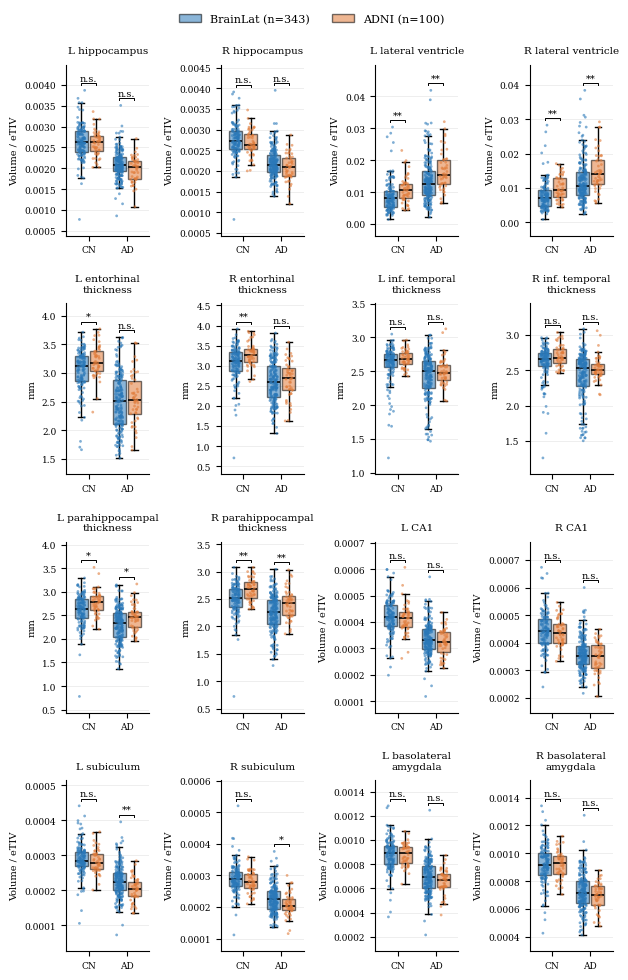

,estructura,grupo,n_BrainLat,mediana_BrainLat,n_ADNI,mediana_ADNI,p,p_fdr
0,hippocampus_L,CN,137,0.0026,50,0.0026,0.4247,0.5040
1,hippocampus_L,AD,206,0.0021,50,0.0020,0.0287,0.0706
2,hippocampus_R,CN,137,0.0027,50,0.0026,0.2332,0.3410
3,hippocampus_R,AD,206,0.0021,50,0.0021,0.0803,0.1643
4,lat_ventricle_L,CN,137,0.0081,50,0.0107,0.0002,0.0022
5,lat_ventricle_L,AD,206,0.0124,50,0.0154,0.0004,0.0026
6,lat_ventricle_R,CN,137,0.0071,50,0.0093,0.0000,0.0013
7,lat_ventricle_R,AD,206,0.0106,50,0.0140,0.0006,0.0030
8,entorhinal_thk_L,CN,137,3.1250,50,3.1805,0.0127,0.0338
9,entorhinal_thk_L,AD,206,2.5155,50,2.5190,0.5568,0.6144


In [ ]:
# --- Pruebas BrainLat vs ADNI dentro de cada grupo
rows = []
for col in STRUCTURES:
    for g in GROUPS:
        a = data.loc[(data["dataset"] == DATASETS[0]) & (data["group"] == g), col].dropna()
        b = data.loc[(data["dataset"] == DATASETS[1]) & (data["group"] == g), col].dropna()
        p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue if len(a) and len(b) else np.nan
        rows.append({"estructura": col, "grupo": g,
                     "n_" + DATASETS[0]: len(a), "mediana_" + DATASETS[0]: a.median(),
                     "n_" + DATASETS[1]: len(b), "mediana_" + DATASETS[1]: b.median(), "p": p})
tests = pd.DataFrame(rows)
ok = tests["p"].notna()
tests["p_fdr"] = np.nan
tests.loc[ok, "p_fdr"] = stats.false_discovery_control(tests.loc[ok, "p"], method="bh")
tests.to_csv(FIG_DIR / "pruebas_brainlat_vs_adni.csv", index=False)

def stars(p):
    if pd.isna(p): return ""
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."

def draw_box(ax, col, show_legend=True):
    width, offset = 0.34, 0.2
    rng = np.random.default_rng(0)
    ann_top = None
    for gi, g in enumerate(GROUPS):
        tops = []
        for di, d in enumerate(DATASETS):
            vals = data.loc[(data["dataset"] == d) & (data["group"] == g), col].dropna().values
            pos = gi + (di - 0.5) * 2 * offset
            if len(vals) == 0:
                continue
            bp = ax.boxplot(vals, positions=[pos], widths=width, patch_artist=True,
                            showfliers=not SHOW_POINTS, manage_ticks=False,
                            medianprops=dict(color="black", linewidth=1.2),
                            flierprops=dict(marker="o", markersize=2, alpha=0.5))
            for patch in bp["boxes"]:
                patch.set_facecolor(COLORS[d]); patch.set_alpha(0.55); patch.set_edgecolor("black")
            if SHOW_POINTS:
                ax.scatter(pos + rng.uniform(-width / 3.5, width / 3.5, len(vals)), vals,
                           s=4, color=COLORS[d], edgecolor="none", alpha=0.6, zorder=3)
            tops.append(vals.max())
        if ANNOTATE_P and len(tops) == 2:
            p = tests.loc[(tests["estructura"] == col) & (tests["grupo"] == g), "p_fdr"].iloc[0]
            allv = data[col].dropna()
            ylo, yhi = allv.min(), allv.max()
            y = max(tops) + 0.04 * (yhi - ylo)
            x1, x2 = gi - offset, gi + offset
            ax.plot([x1, x1, x2, x2], [y, y + 0.015 * (yhi - ylo), y + 0.015 * (yhi - ylo), y],
                    color="black", linewidth=0.7)
            ax.text(gi, y + 0.02 * (yhi - ylo), stars(p), ha="center", va="bottom", fontsize=7)
            ann_top = max(ann_top if ann_top is not None else -np.inf, y + 0.16 * (yhi - ylo))
    ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels(GROUPS)
    ax.set_xlim(-0.6, len(GROUPS) - 0.4)
    ax.set_title(STRUCTURES[col], pad=6)
    ax.set_ylabel(unit_of(col))
    ax.margins(y=0.12)
    if ann_top is not None:
        ax.set_ylim(top=max(ax.get_ylim()[1], ann_top))
    ax.grid(axis="y", alpha=0.3, linewidth=0.5)
    if show_legend:
        ax.legend(handles=legend_handles(), loc="lower center", bbox_to_anchor=(0.5, -0.32),
                  ncol=len(DATASETS), frameon=False)

def legend_handles():
    return [Patch(facecolor=COLORS[d], alpha=0.55, edgecolor="black",
                  label="{} (n={})".format(d, int((data["dataset"] == d).sum()))) for d in DATASETS]

# --- 1) Una figura por estructura
for col in STRUCTURES:
    fig, ax = plt.subplots(figsize=(FIG_W_SINGLE, 2.8))
    draw_box(ax, col)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "{}.pdf".format(col), bbox_inches="tight")
    plt.close(fig)
print("PDF individuales guardados en {}/".format(FIG_DIR))

# --- 2) Figura panel con todas las estructuras
import textwrap
n = len(STRUCTURES)
nrows = int(np.ceil(n / PANEL_COLS))
fig, axes = plt.subplots(nrows, PANEL_COLS, figsize=(FIG_W_PANEL, 2.35 * nrows + 0.4))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, STRUCTURES):
    draw_box(ax, col, show_legend=False)
    ax.set_title(textwrap.fill(STRUCTURES[col], 20), fontsize=7.5, pad=8)
    ax.tick_params(labelsize=6.5); ax.yaxis.label.set_size(7)
for ax in axes[n:]:
    ax.axis("off")
fig.legend(handles=legend_handles(), loc="upper center", ncol=len(DATASETS), frameon=False,
           bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=1.6, w_pad=1.2)
fig.savefig(FIG_DIR / "panel_estructuras.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

display(tests.round(4))

## Parte 7 — Tabla demográfica en LaTeX

Por dataset y grupo: N, edad (media ± DE), sexo (n y % del sexo `SEX_REPORT`) y años de educación (media ± DE). Si `ADD_PVALUES = True` se agrega una columna *p* por dataset comparando CN vs AD: prueba *t* de Welch para edad y educación, χ² para sexo (o Fisher exacta si alguna frecuencia esperada es < 5).

Requiere en el preámbulo: `\usepackage{booktabs}` (y `\usepackage{multirow}` no es necesario). Se guarda en `tabla_demografica.tex` y también en CSV.

In [ ]:
def mean_sd(x):
    x = x.dropna()
    if len(x) == 0:
        return "--"
    return "{:.{d}f} $\\pm$ {:.{d}f}".format(x.mean(), x.std(ddof=1), d=DECIMALS)

def n_pct(s):
    s = s.dropna()
    if len(s) == 0:
        return "--"
    k = int((s == SEX_REPORT).sum())
    return "{} ({:.1f}\\%)".format(k, 100 * k / len(s))

def fmt_p(p):
    if pd.isna(p): return "--"
    return "$<$0.001" if p < 0.001 else "{:.3f}".format(p)

def p_continuous(d, col):
    a = d.loc[d["group"] == GROUPS[0], col].dropna(); b = d.loc[d["group"] == GROUPS[1], col].dropna()
    return stats.ttest_ind(a, b, equal_var=False).pvalue if len(a) > 1 and len(b) > 1 else np.nan

def p_sex(d):
    ct = pd.crosstab(d["group"], d[SEX_COL])   # crosstab ignora los faltantes
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2, p, _, expected = stats.chi2_contingency(ct, correction=False)
    if ct.shape == (2, 2) and (expected < 5).any():
        p = stats.fisher_exact(ct.values)[1]
    return p

sex_label = "Sexo, {} n (\\%)".format({"F": "mujeres", "M": "hombres"}.get(SEX_REPORT, SEX_REPORT))
row_labels = ["N", "Edad (años)", sex_label, "Educación (años)"]
cells, csv_rows = {}, []
for ds in DATASETS:
    d = data[data["dataset"] == ds]
    for g in GROUPS:
        dg = d[d["group"] == g]
        cells[(ds, g)] = [str(len(dg)), mean_sd(dg[AGE_COL]), n_pct(dg[SEX_COL]), mean_sd(dg[EDU_COL])]
    cells[(ds, "p")] = ["", fmt_p(p_continuous(d, AGE_COL)), fmt_p(p_sex(d)), fmt_p(p_continuous(d, EDU_COL))]

sub = GROUPS + (["$p$"] if ADD_PVALUES else [])
keys = GROUPS + (["p"] if ADD_PVALUES else [])
ncols = len(sub)

lines = [
    "\\begin{table}[htbp]",
    "\\centering",
    "\\caption{Características demográficas por dataset y grupo diagnóstico. "
    "Edad y educación: media $\\pm$ DE." + (" $p$: CN vs.\\ AD (\\textit{t} de Welch; "
    "$\\chi^2$ o Fisher para sexo)." if ADD_PVALUES else "") + "}",
    "\\label{tab:demografia}",
    "\\begin{tabular}{l" + ("c" * ncols) * len(DATASETS) + "}",
    "\\toprule",
    " & " + " & ".join("\\multicolumn{{{}}}{{c}}{{{}}}".format(ncols, ds) for ds in DATASETS) + " \\\\",
    " ".join("\\cmidrule(lr){{{}-{}}}".format(2 + i * ncols, 1 + (i + 1) * ncols) for i in range(len(DATASETS))),
    " & " + " & ".join(sub * len(DATASETS)) + " \\\\",
    "\\midrule",
]
for r, label in enumerate(row_labels):
    vals = [cells[(ds, k)][r] for ds in DATASETS for k in keys]
    lines.append(label + " & " + " & ".join(vals) + " \\\\")
    csv_rows.append({"Variable": label.replace("\\%", "%"),
                     **{"{} {}".format(ds, k): cells[(ds, k)][r].replace("$\\pm$", "±").replace("\\%", "%").replace("$<$", "<")
                        for ds in DATASETS for k in keys}})
lines += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
latex = "\n".join(lines)

(OUT_DIR / "tabla_demografica.tex").write_text(latex, encoding="utf-8")
demo_table = pd.DataFrame(csv_rows).set_index("Variable")
demo_table.to_csv(OUT_DIR / "tabla_demografica.csv")
display(demo_table)
print("\n% ---- Copia esto en tu .tex (requiere \\usepackage{booktabs}) ----\n")
print(latex)

,BrainLat CN,BrainLat AD,BrainLat p,ADNI CN,ADNI AD,ADNI p
Variable,,,,,,
N,137,206,,50,50,
Edad (años),69.4 ± 8.0,73.3 ± 8.1,<0.001,75.1 ± 5.0,75.1 ± 5.0,0.998
"Sexo, mujeres n (%)",0 (0.0%),0 (0.0%),0.667,0 (0.0%),0 (0.0%),1.000
Educación (años),13.6 ± 4.2,11.8 ± 4.5,<0.001,15.9 ± 2.4,15.8 ± 2.3,0.832



% ---- Copia esto en tu .tex (requiere \usepackage{booktabs}) ----

\begin{table}[htbp]
\centering
\caption{Características demográficas por dataset y grupo diagnóstico. Edad y educación: media $\pm$ DE. $p$: CN vs.\ AD (\textit{t} de Welch; $\chi^2$ o Fisher para sexo).}
\label{tab:demografia}
\begin{tabular}{lcccccc}
\toprule
 & \multicolumn{3}{c}{BrainLat} & \multicolumn{3}{c}{ADNI} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
 & CN & AD & $p$ & CN & AD & $p$ \\
\midrule
N & 137 & 206 &  & 50 & 50 &  \\
Edad (años) & 69.4 $\pm$ 8.0 & 73.3 $\pm$ 8.1 & $<$0.001 & 75.1 $\pm$ 5.0 & 75.1 $\pm$ 5.0 & 0.998 \\
Sexo, mujeres n (\%) & 0 (0.0\%) & 0 (0.0\%) & 0.667 & 0 (0.0\%) & 0 (0.0\%) & 1.000 \\
Educación (años) & 13.6 $\pm$ 4.2 & 11.8 $\pm$ 4.5 & $<$0.001 & 15.9 $\pm$ 2.4 & 15.8 $\pm$ 2.3 & 0.832 \\
\bottomrule
\end{tabular}
\end{table}


## Parte 8 — Descargar resultados

Descarga un `.zip` con los PDF de los boxplots, la tabla `.tex` y los CSV. En LaTeX:

```latex
\begin{figure}[htbp]
  \centering
  \includegraphics[width=\textwidth]{boxplots/panel_estructuras.pdf}
  \caption{Distribución de las estructuras de FreeSurfer en BrainLat y ADNI por grupo (CN / AD).}
  \label{fig:boxplots}
\end{figure}

\input{tabla_demografica.tex}
```

In [ ]:
shutil.make_archive(str(OUT_DIR), "zip", OUT_DIR)
files.download("{}.zip".format(OUT_DIR))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>